In [1]:
from utils.library import *
from utils.download import *
from utils.metrics import split_temporal
from utils.stock_config import *
from models.arima import *
from models.xgboost import run_xgbooster
from utils.plots import plot_forecast, plot_forecast_30
from models.lstm import run_lstm, run_lstm_30
from models.shap import explain_variables

c:\TCC\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Buscando os dados

In [2]:
itub_csv = 'data/itub.csv'

if not os.path.exists(itub_csv):
    itub4_dataset = load_stock(STOCKS["itub"], "itub", force=True)
    itub4_dataset.head(10)

itub4_dataset = pd.read_csv(itub_csv)

In [3]:
itub4_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 3439 entries, 0 to 3438
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          3439 non-null   str    
 1   itub_close    3439 non-null   float64
 2   itub_high     3439 non-null   float64
 3   itub_low      3439 non-null   float64
 4   itub_open     3439 non-null   float64
 5   itub_volume   3439 non-null   int64  
 6   ibovespa      3439 non-null   float64
 7   vix           3439 non-null   float64
 8   selic_daily   3439 non-null   float64
 9   selic_goal    3439 non-null   float64
 10  ipca          3439 non-null   float64
 11  fx_usd        3439 non-null   float64
 12  gdp           3439 non-null   float64
 13  unemployment  3439 non-null   float64
dtypes: float64(12), int64(1), str(1)
memory usage: 376.3 KB


## ARIMA

--- Identificando ordem do ARIMA para ITUB ---
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=805.964, Time=1.43 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=830.032, Time=0.14 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=823.307, Time=0.07 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=823.426, Time=0.13 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=828.440, Time=0.05 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=827.169, Time=0.20 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=827.213, Time=0.22 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=824.734, Time=1.55 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.22 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=825.167, Time=0.15 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=821.005, Time=0.86 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=826.519, Time=0.62 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.74 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=804.398, Time=0.52 sec
 ARIMA(1

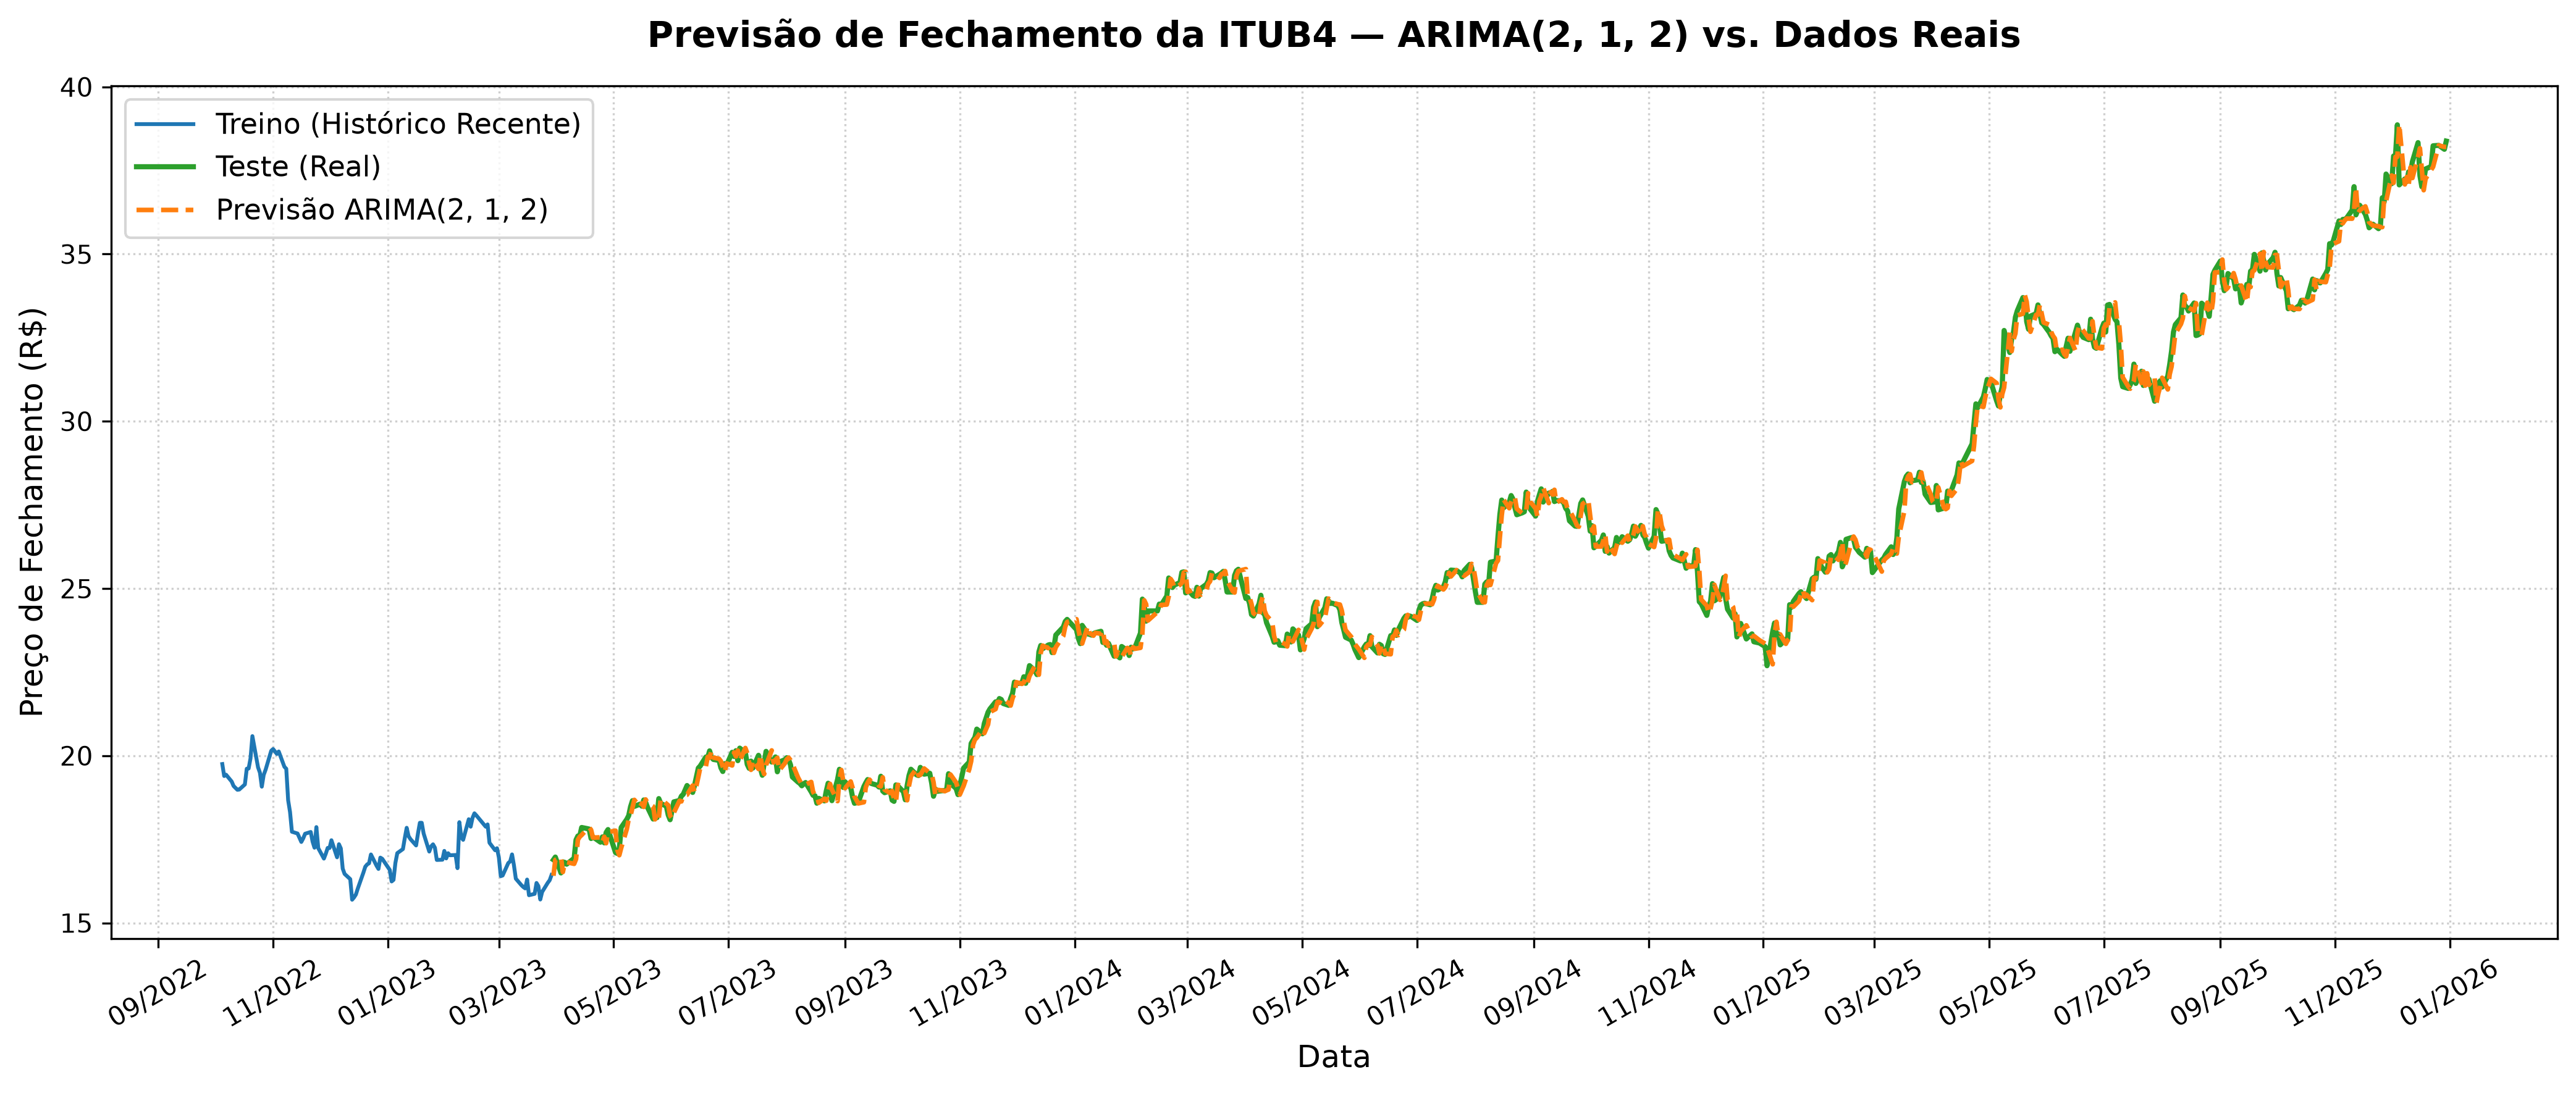

In [4]:
train_itub, test_itub = split_temporal(itub4_dataset)
res_itub = run_arima(train_itub, test_itub, "itub")
plot_forecast(
    train_itub, test_itub,
    predictions=res_itub["predictions"],
    stock_name="itub",
    model_name=f"ARIMA{res_itub['order']}",
    ticker_label="ITUB4",
)

ARIMA(2, 1, 2) | horizonte = 30 dias
ARIMA(2, 1, 2) itub h=30 RMSE: 1.9314 | MAE: 1.5618 | MAPE: 5.89% | Acurácia direcional: 46.43%
dict_keys(['stock', 'order', 'horizon', 'model', 'backtest', 'futuro', 'path', 'path_ci', 'real_path', 'predictions', 'real', 'baseline', 'rmse', 'mae', 'mape', 'dir_acc'])


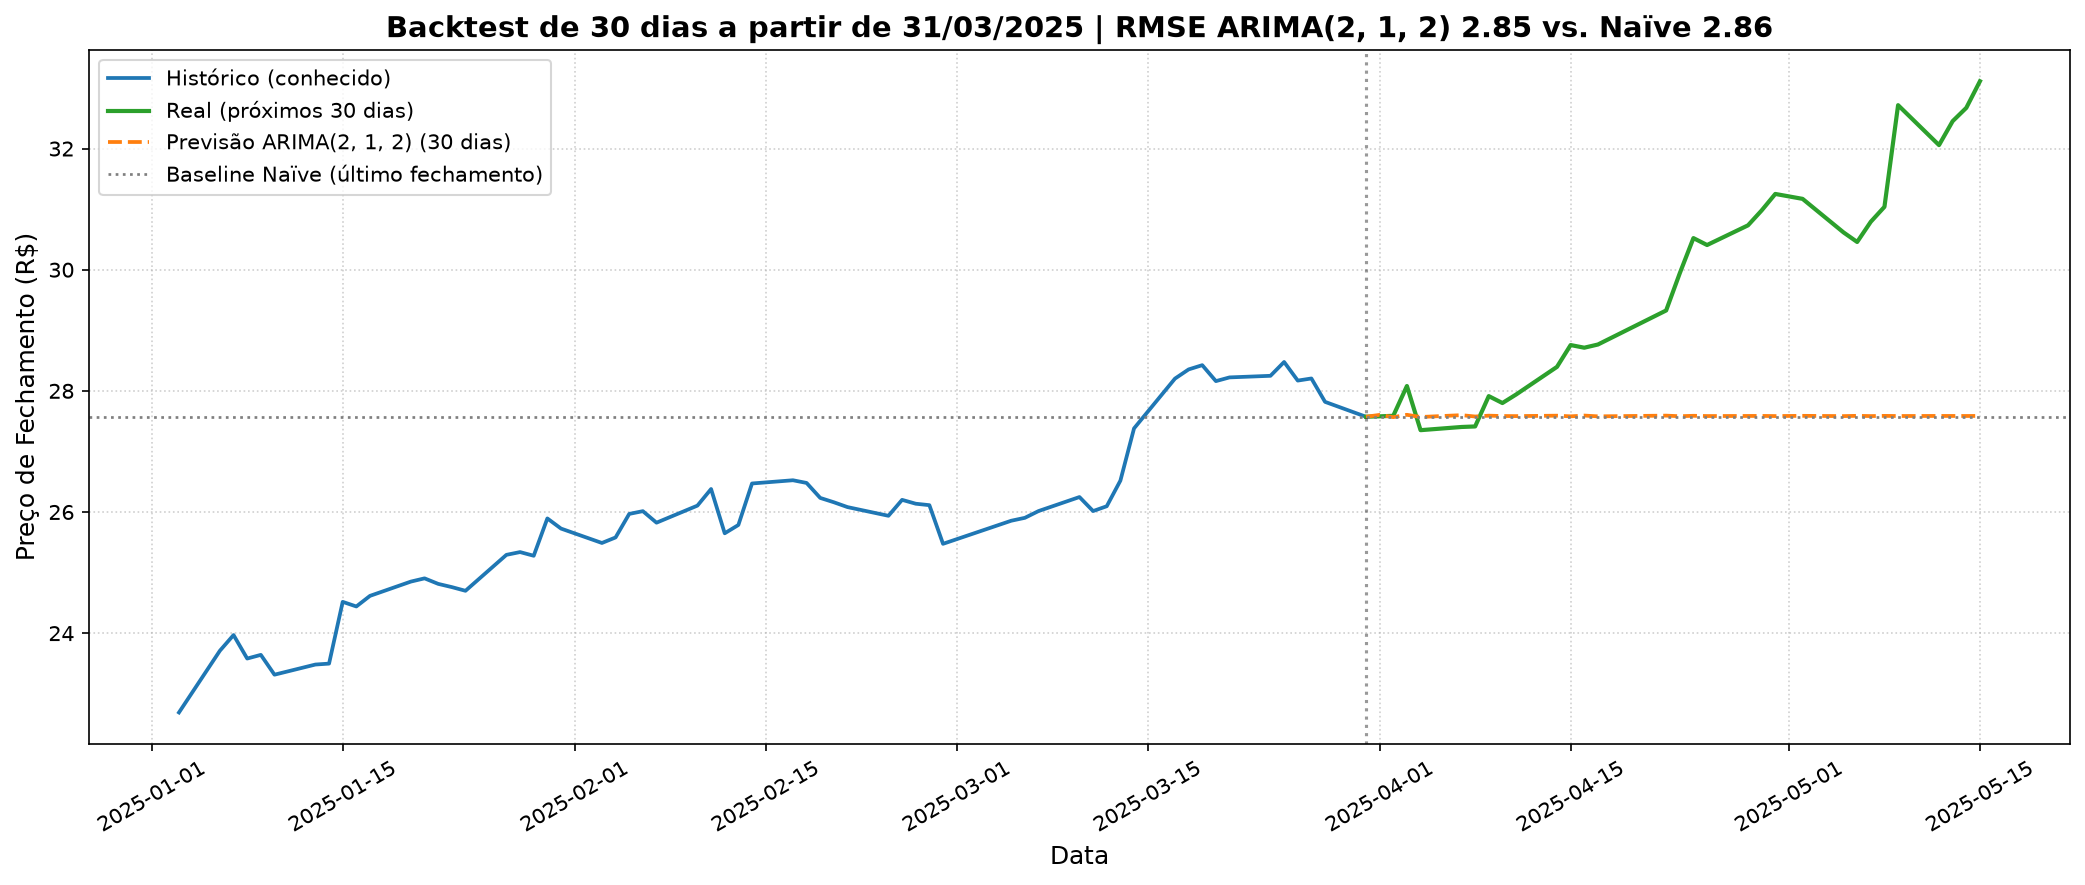

In [5]:
res_itub_30 = run_arima_30(train_itub, test_itub, "itub", horizon=30)
print(res_itub_30.keys())   # deve listar 'backtest' e 'futuro'

plot_forecast_30(res_itub_30, train_itub, test_itub, "itub", origem="2025-03-31",
                 model_name=f"ARIMA{res_itub_30['order']}")

## XGBooster

--- XGBoost ITUB: 37 features, 2748 treino / 688 teste ---
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Melhores hiperparâmetros: {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 300, 'subsample': 1.0}
Melhor RMSE médio (validação): 1.6237
XGBoost itub           RMSE: 6.6969 | MAE: 4.7970 | MAPE: 15.77% | Acurácia direcional: 47.24%
Naive itub             RMSE: 0.3285 | MAE: 0.2446 | MAPE: 0.95% | Acurácia direcional: n/a
p-valor (teste binomial, acurácia direcional): 0.1583


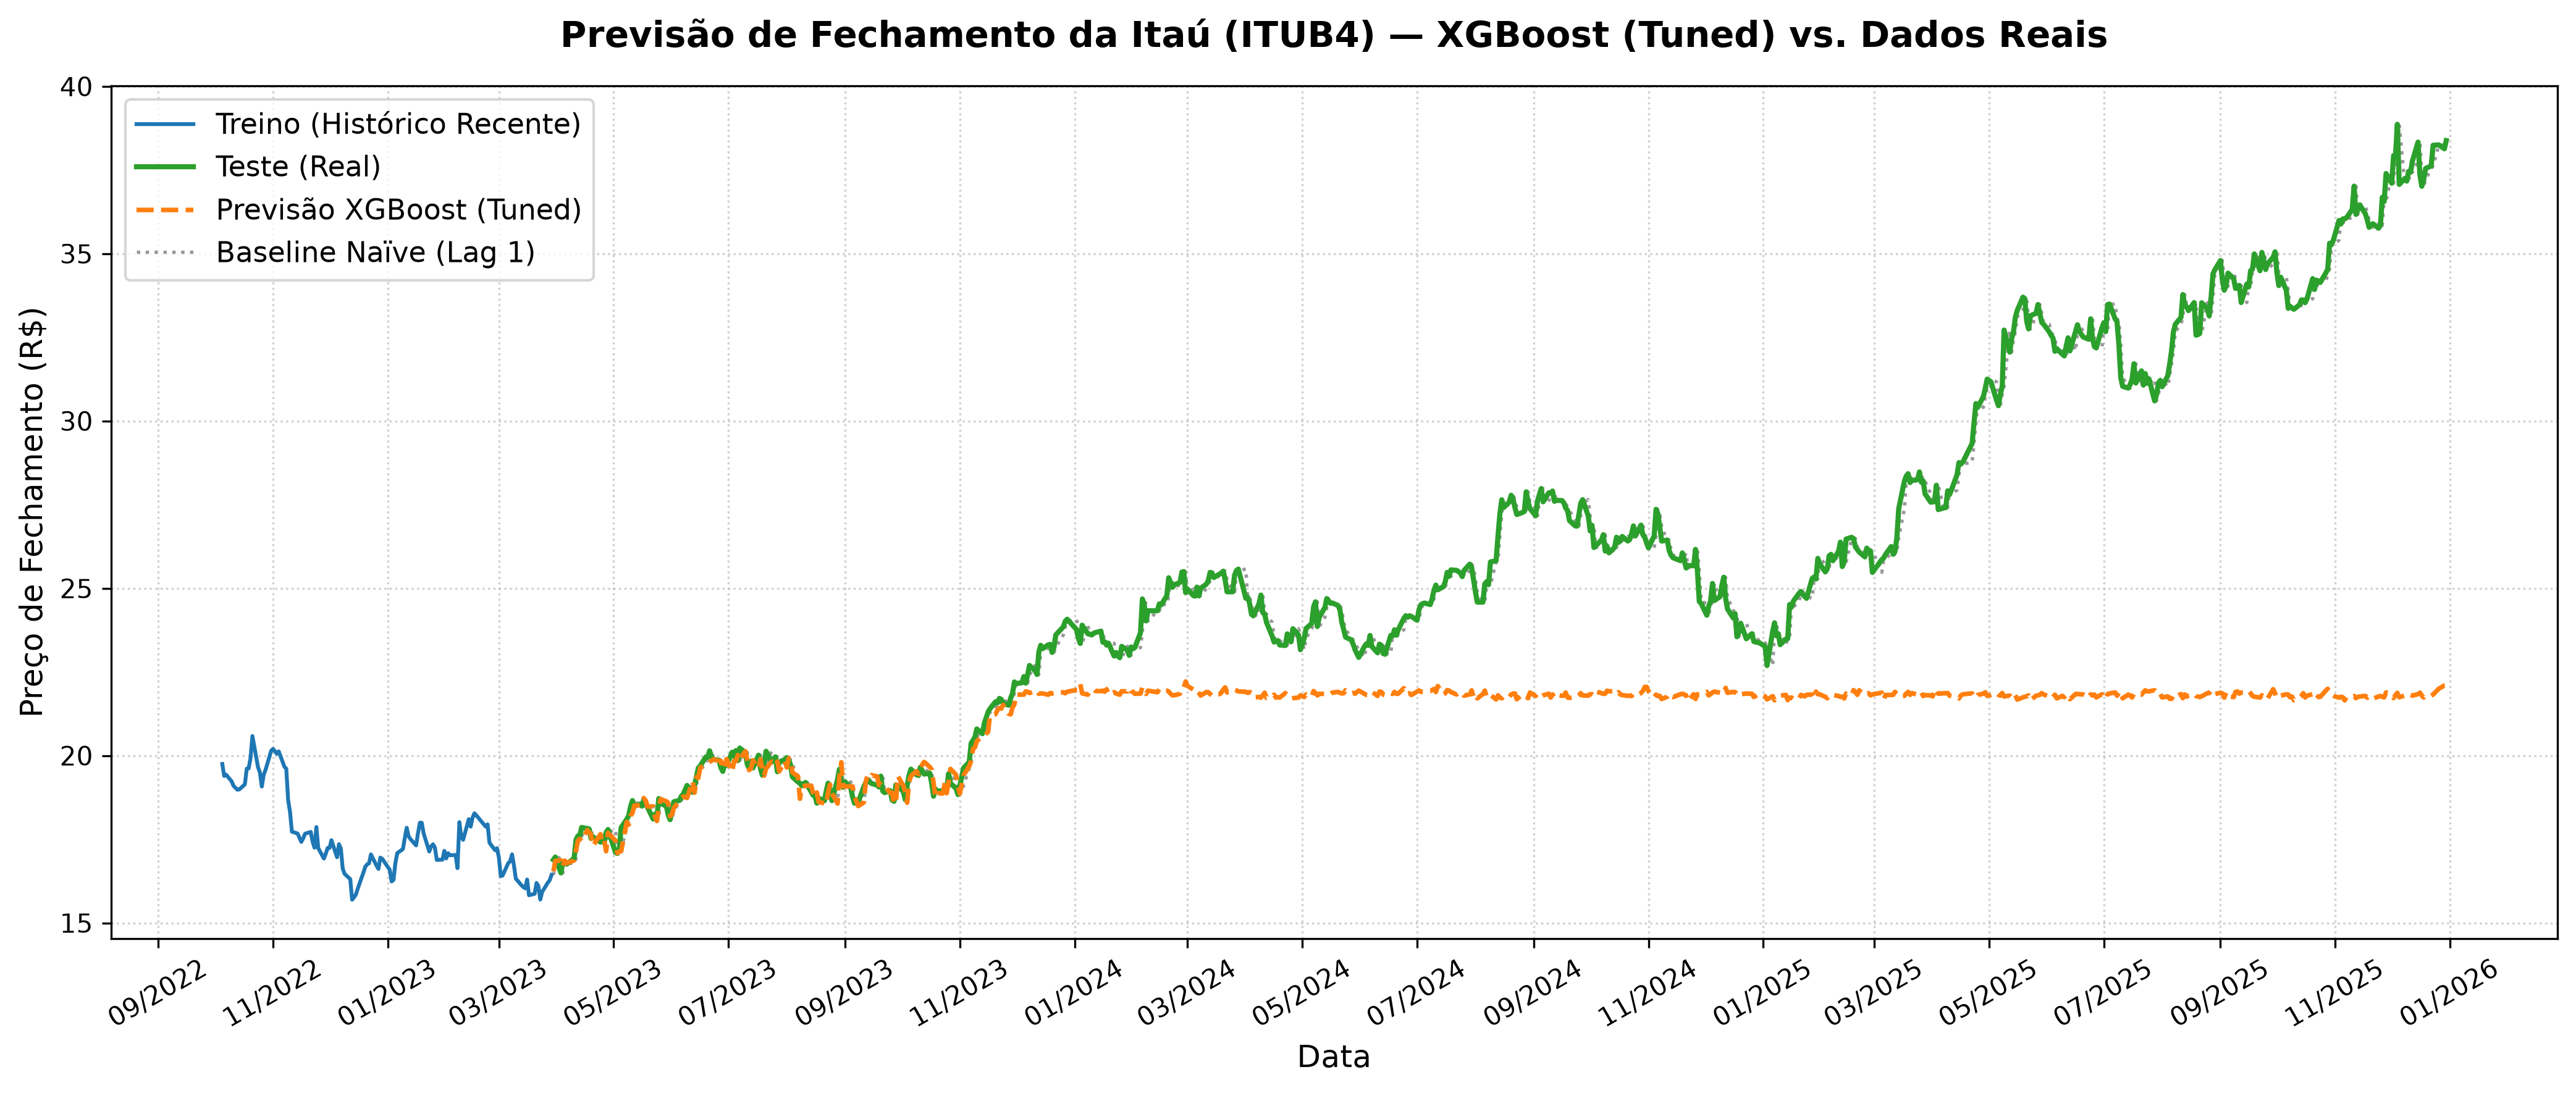

In [6]:
res_xgbooster = run_xgbooster(train_itub, test_itub, "itub")
plot_forecast(
    train_itub, test_itub,
    predictions=res_xgbooster["predictions"],
    stock_name="itub",
    model_name="XGBoost (Tuned)",
    ticker_label="ITUB4",
    company_name="Itaú",
    baseline=res_xgbooster["ontem"],        # baseline naive (preço de ontem)
)

## LSTM

Keras backend: torch | dispositivo: NVIDIA GeForce RTX 3050 6GB Laptop GPU
--- LSTM ITUB: treino (2318, 20, 13), val (413, 20, 13), teste (688, 20, 13) ---
Reloading Tuner from lstm_tuning\itub_lstm\tuner0.json
Melhores hiperparâmetros: {'n_layers': 1, 'units_0': 32, 'dropout_0': 0.0, 'learning_rate': 0.01, 'units_1': 192, 'dropout_1': 0.1, 'units_2': 224, 'dropout_2': 0.30000000000000004, 'tuner/epochs': 10, 'tuner/initial_epoch': 4, 'tuner/bracket': 1, 'tuner/round': 1, 'tuner/trial_id': '0022'}
Epoch 1/100
 1/37 ━━━━━━━━━━━━━━━━━━━━ 7s 200ms/step - loss: 0.2295 - mae: 0.3422

c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1481.)
  outputs, h_n, c_n = torch._VF.lstm(


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0154 - mae: 0.0714 - val_loss: 0.0027 - val_mae: 0.0414
Epoch 2/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.6648e-04 - mae: 0.0218 - val_loss: 0.0040 - val_mae: 0.0538
Epoch 3/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 5.4576e-04 - mae: 0.0172 - val_loss: 0.0031 - val_mae: 0.0470
Epoch 4/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 5.0337e-04 - mae: 0.0164 - val_loss: 0.0016 - val_mae: 0.0319
Epoch 5/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 4.5521e-04 - mae: 0.0155 - val_loss: 0.0019 - val_mae: 0.0353
Epoch 6/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 4.3783e-04 - mae: 0.0152 - val_loss: 0.0015 - val_mae: 0.0320
Epoch 7/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 4.6813e-04 - mae: 0.0156 - val_loss: 0.0017 - val_mae: 0.0344
Epoch 8/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 4.0481e-04 - mae: 0.0145 - val_loss: 0.0019 - val_mae: 0.0364
Epoch 9/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/st

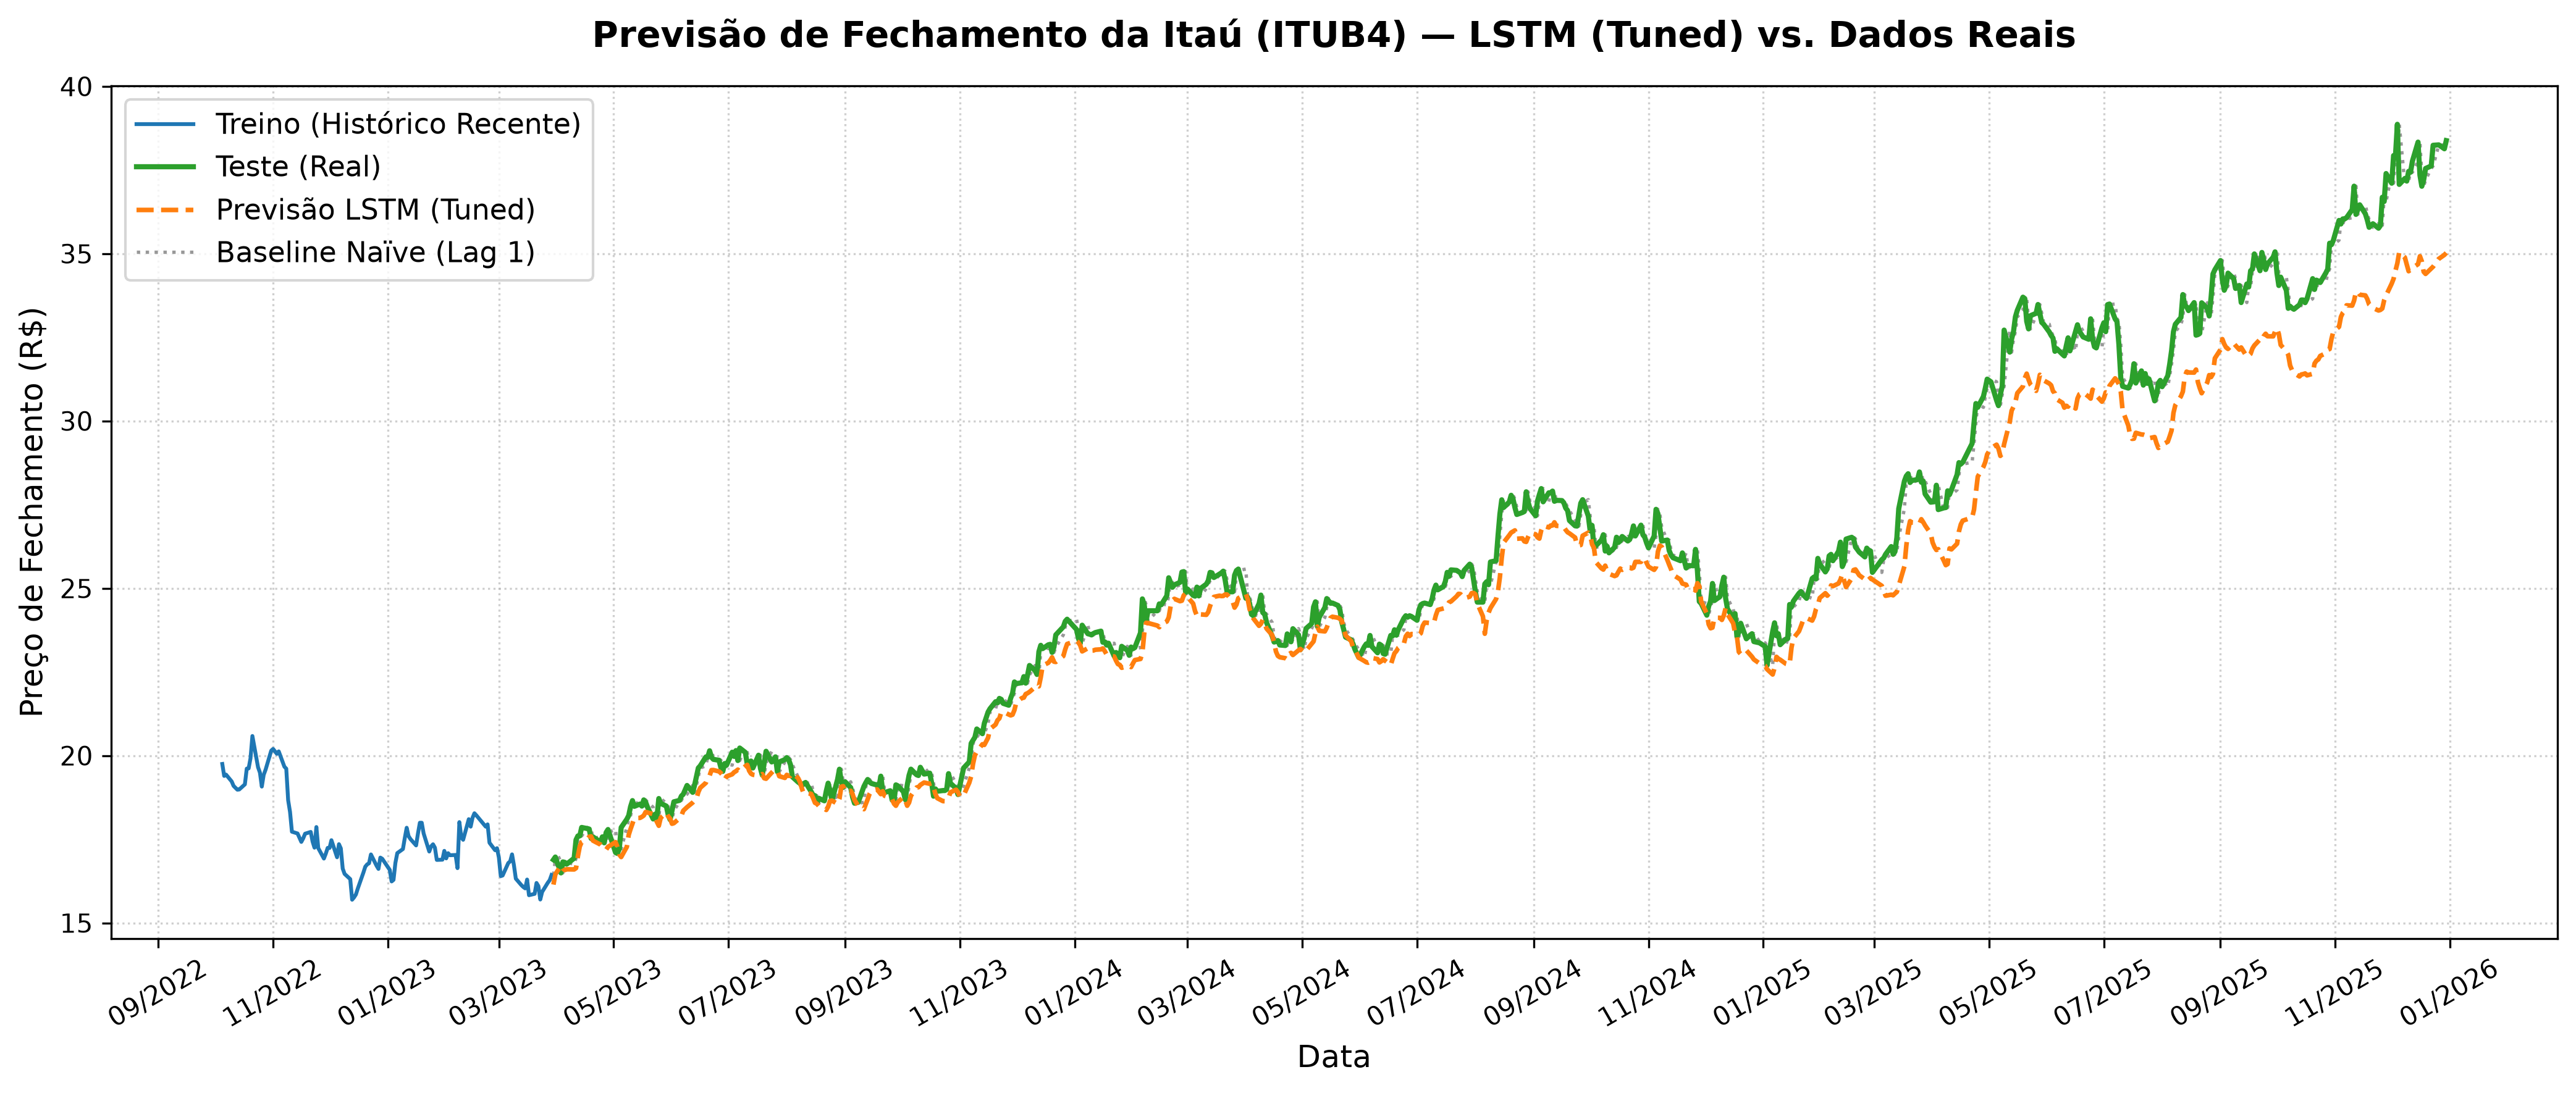

In [7]:
res_lstm = run_lstm(train_itub, test_itub, "itub", max_epochs=10)
plot_forecast(train_itub, test_itub, res_lstm["predictions"], "itub",
              model_name="LSTM (Tuned)", ticker_label="ITUB4",
              company_name="Itaú", baseline=res_lstm["ontem"])

Epoch 1/100
20/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0492

c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1481.)
  outputs, h_n, c_n = torch._VF.lstm(


36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0301 - val_loss: 0.0083
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0039 - val_loss: 0.0068
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0034 - val_loss: 0.0066
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0033 - val_loss: 0.0058
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0032 - val_loss: 0.0069
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0032 - val_loss: 0.0075
Epoch 7/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0031 - val_loss: 0.0071
Epoch 8/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0032 - val_loss: 0.0055
Epoch 9/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0032 - val_loss: 0.0066
Epoch 10/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0031 - val_loss: 0.0059
Epoch 11/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0030 - val_loss: 0.0084
Epoch 12/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0030 - val_lo

c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1481.)
  outputs, h_n, c_n = torch._VF.lstm(
c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1481.)
  outputs, h_n, c_n = torch._VF.lstm(
c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single

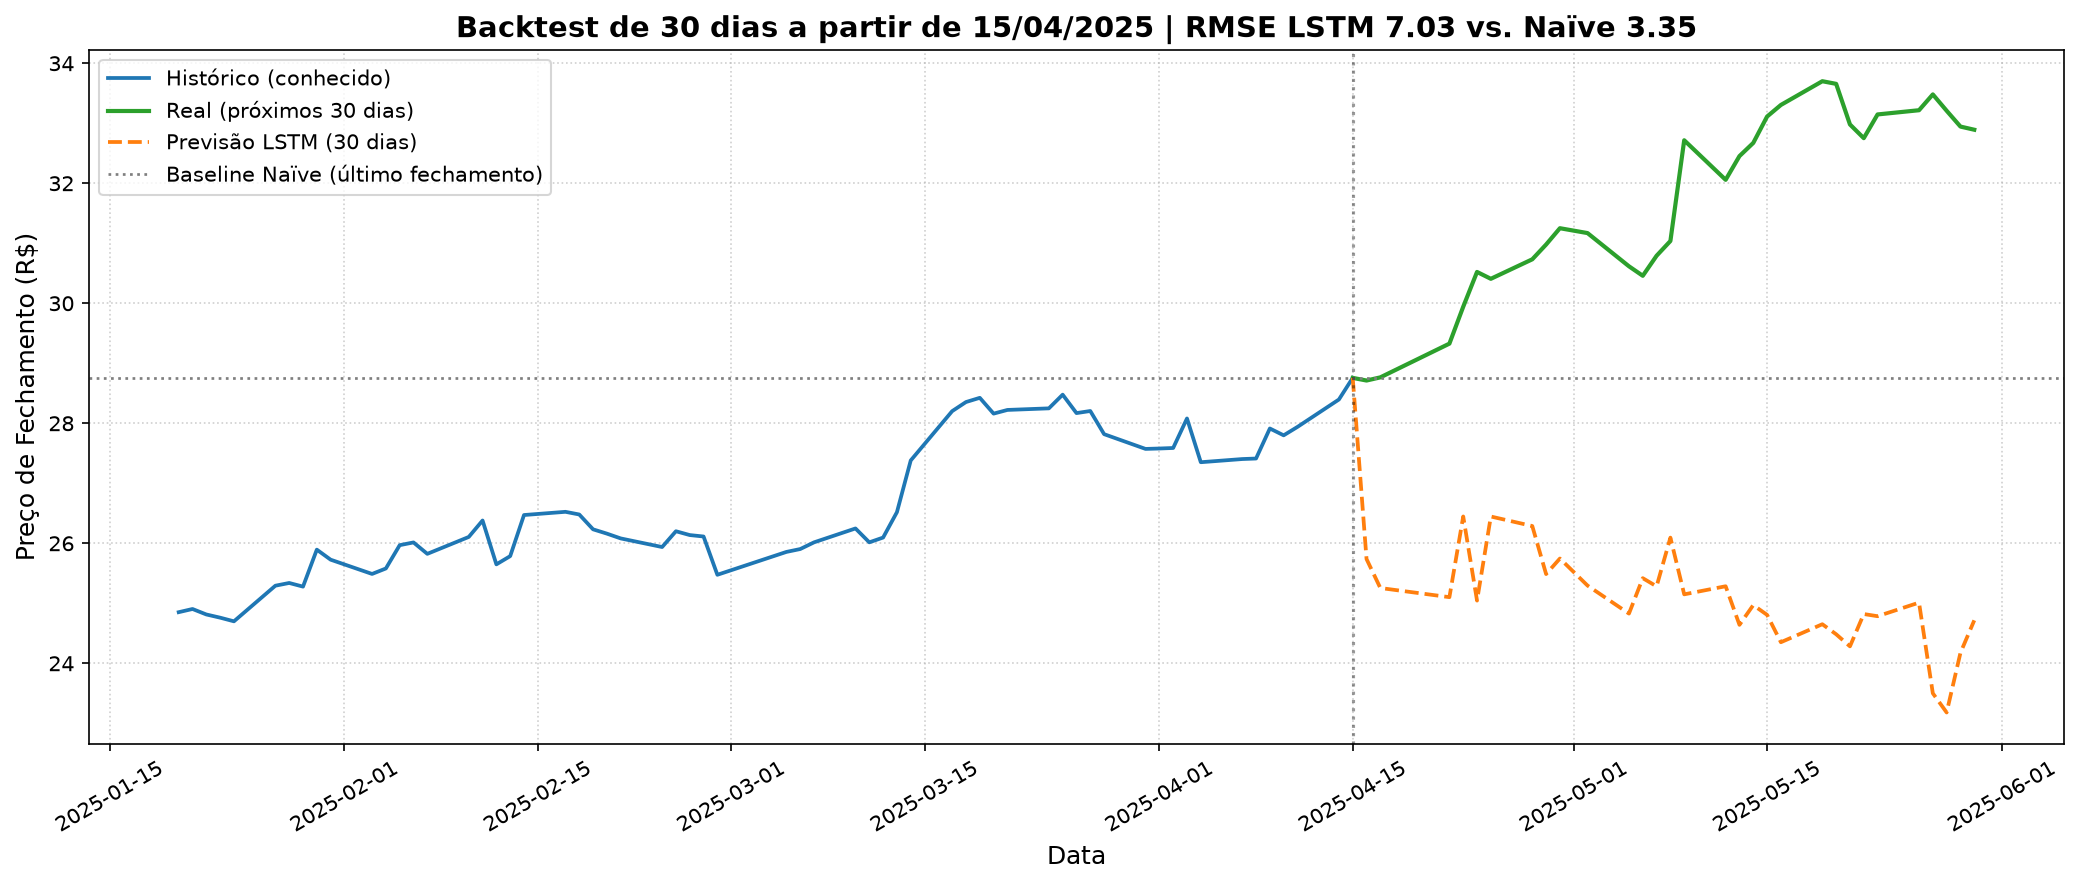

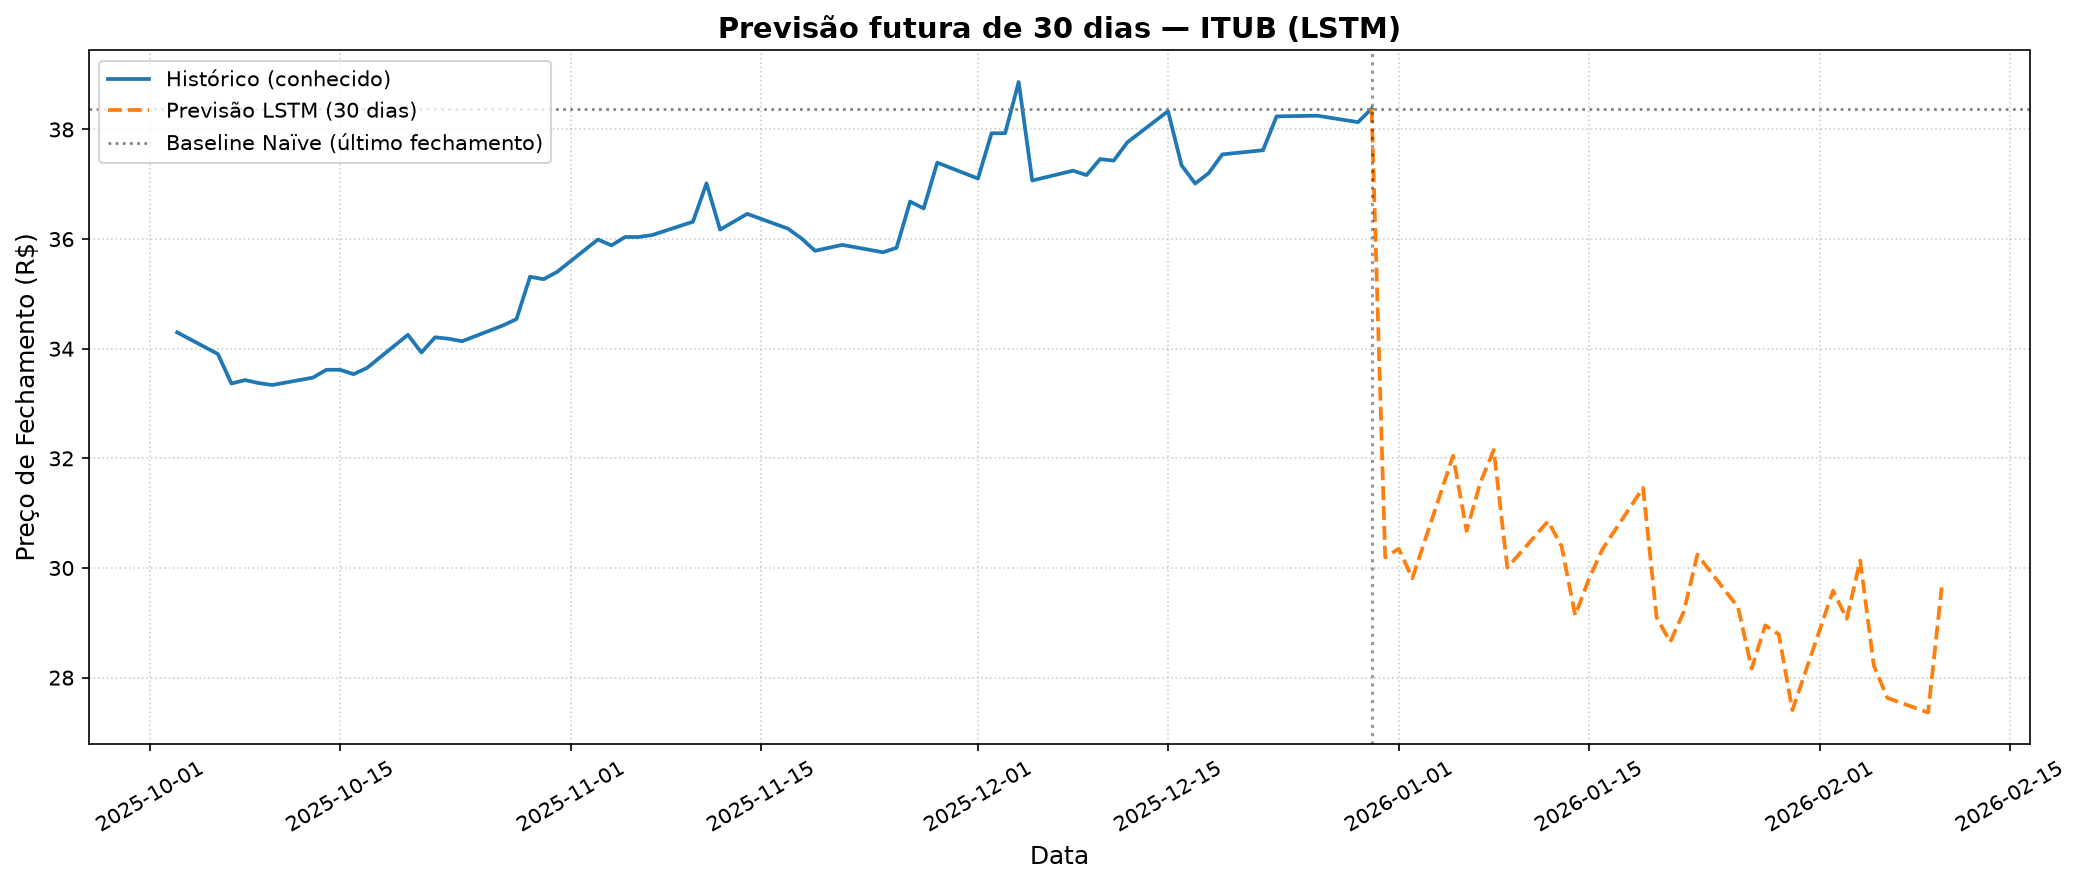

In [8]:
res_lstm_30 = run_lstm_30(train_itub, test_itub, "itub", res_lstm["best_params"])

res_lstm_30["metricas"]                       # RMSE / MAE / MAPE por origem, com o RMSE do naive
res_lstm_30["metricas"].mean(numeric_only=True)

plot_forecast_30(res_lstm_30, train_itub, test_itub, "itub", origem="2025-03-31")   # backtest com preço real
plot_forecast_30(res_lstm_30, train_itub, test_itub, "itub")   

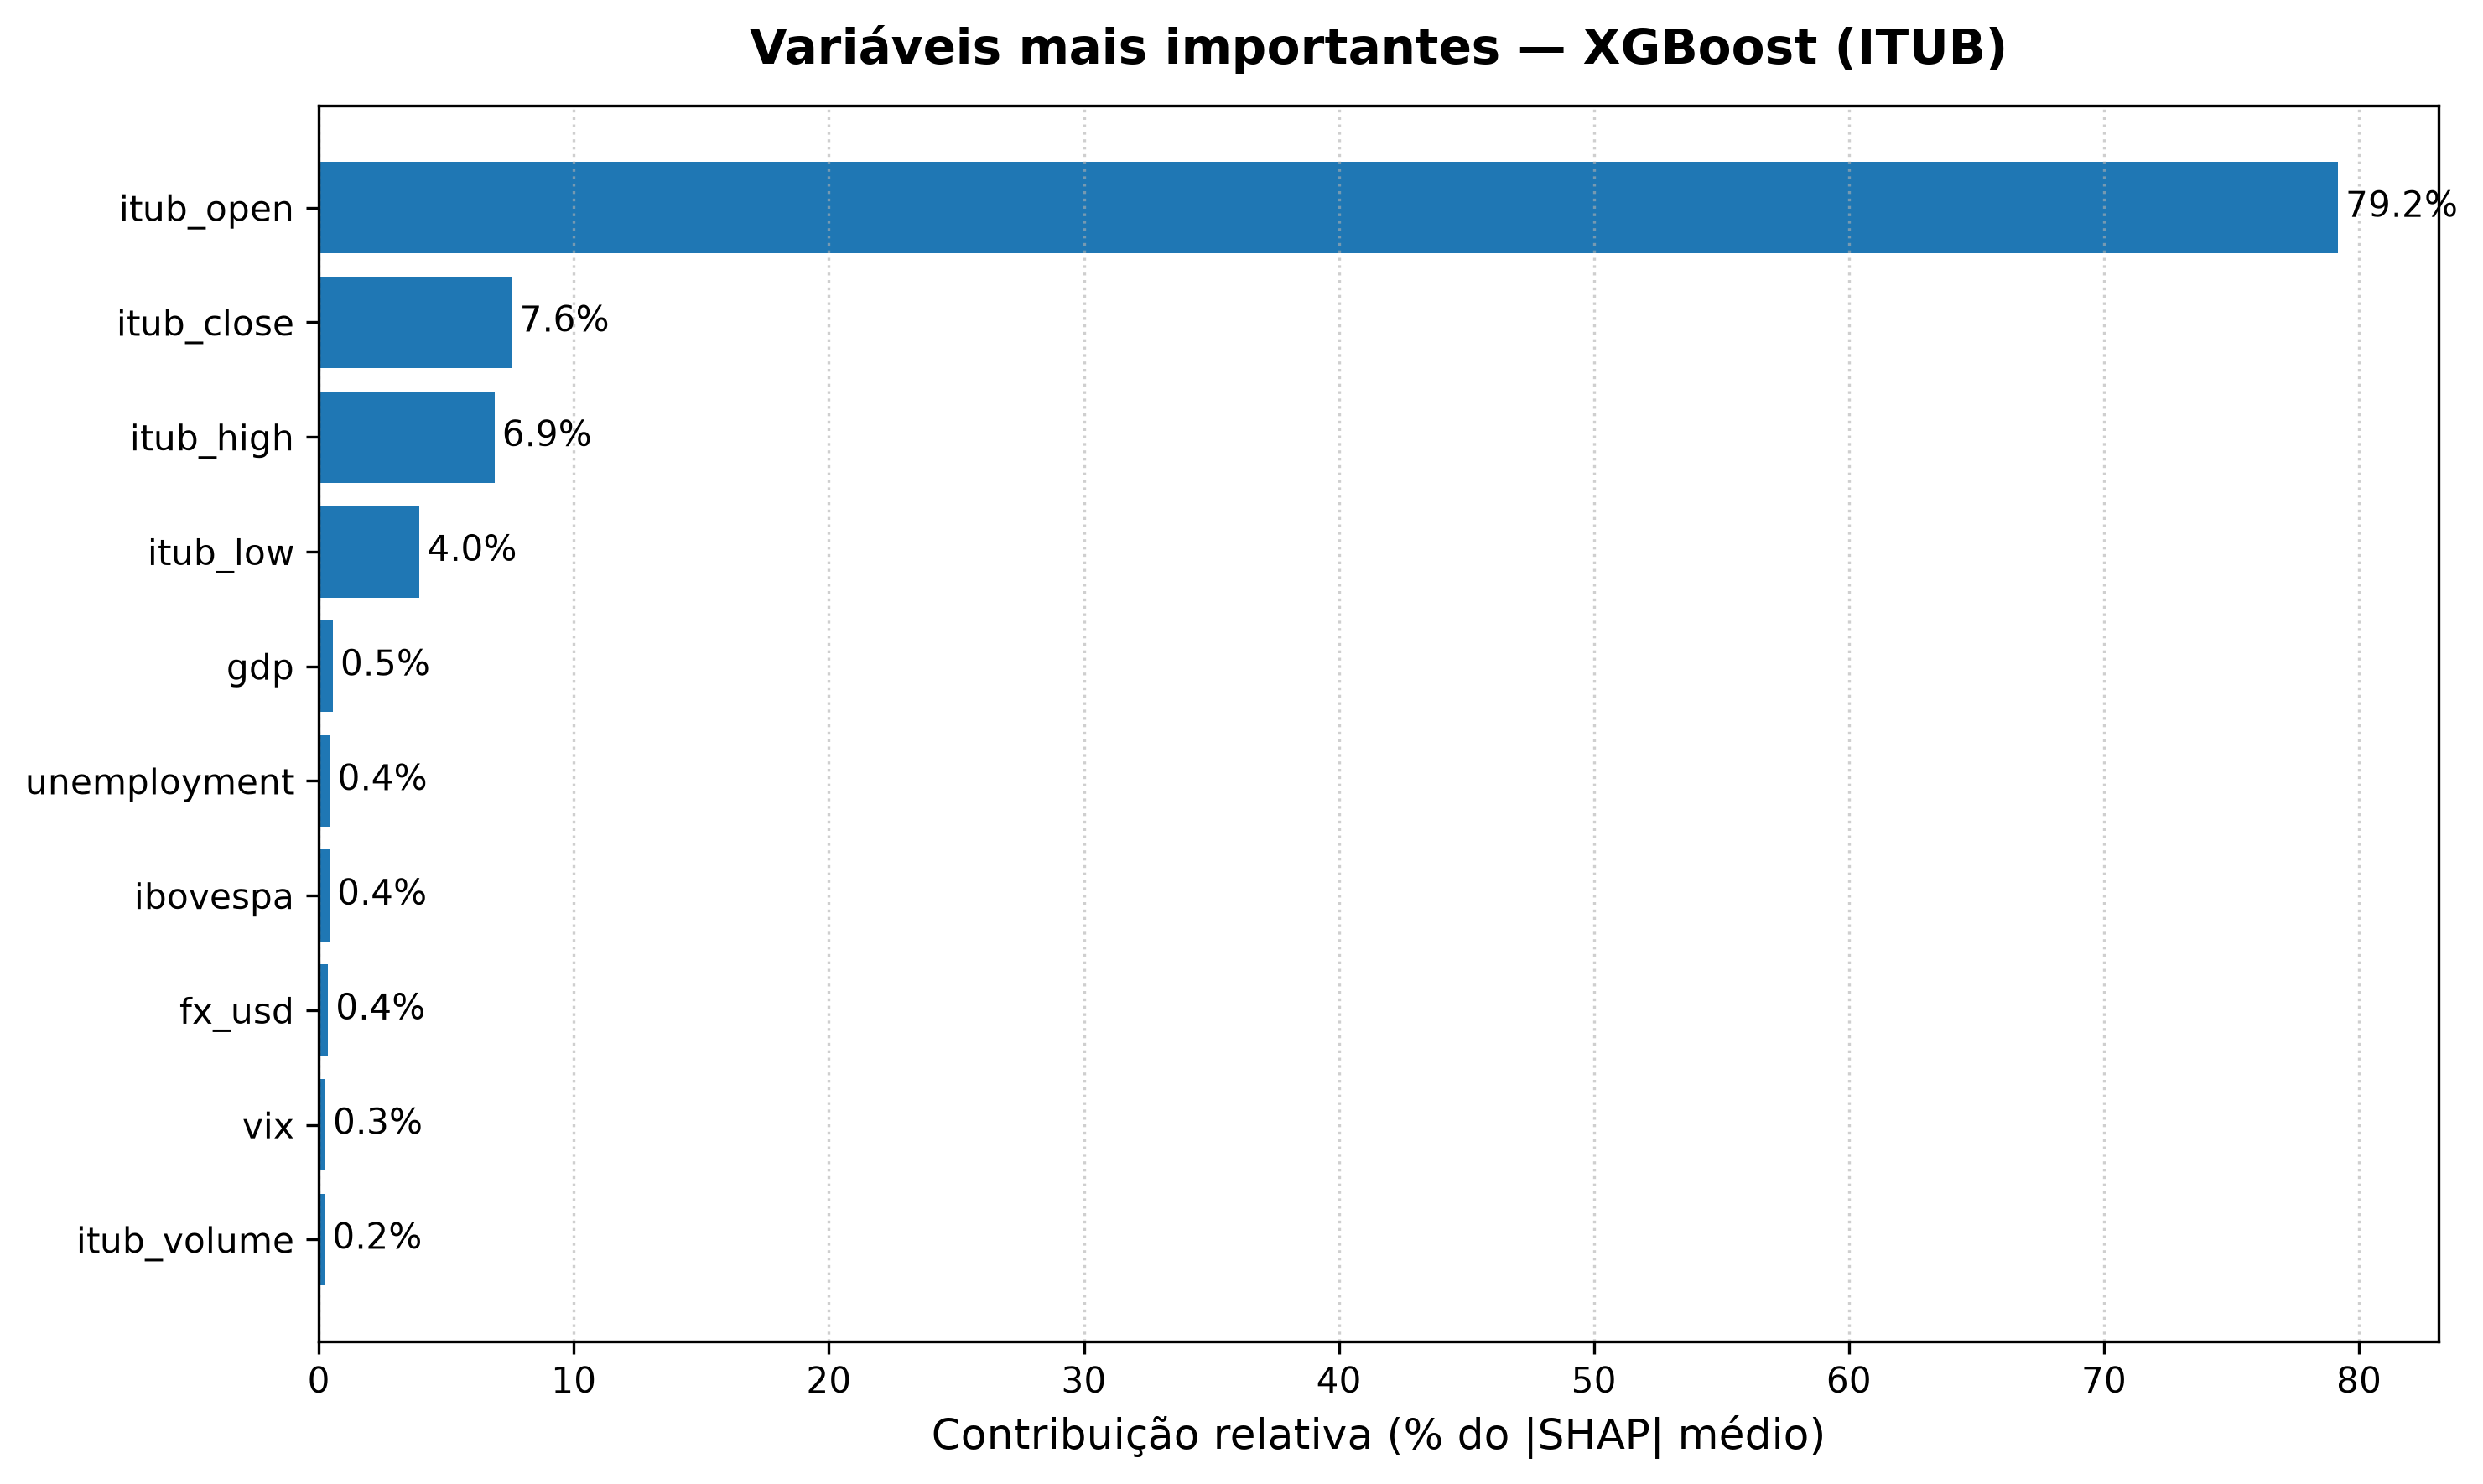

,variavel,mean_abs_shap,pct
0,itub_open,6.580883,79.172211
1,itub_close,0.629532,7.573672
2,itub_high,0.572628,6.889079
3,itub_low,0.328508,3.952157
4,gdp,0.045626,0.548915
5,unemployment,0.036552,0.439748
6,ibovespa,0.035205,0.423534
7,fx_usd,0.030159,0.362833
8,vix,0.021214,0.255220
9,itub_volume,0.019347,0.232755


In [9]:
tab_itub = explain_variables(res_xgbooster)
tab_itub.head(10)